In [1]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv("cifar-10.csv")

In [4]:
df.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [5]:
df.shape

(50000, 3073)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Columns: 3073 entries, pixel_0 to label
dtypes: int64(3073)
memory usage: 1.1 GB


In [7]:
labels = df["label"].values
pixels = df.drop("label",axis=1).values

In [8]:
print(labels.shape)
print(pixels.shape)

(50000,)
(50000, 3072)


In [9]:
pixels = pixels.reshape(-1,3,32,32)

In [10]:
pixels.shape

(50000, 3, 32, 32)

In [11]:
pixels = pixels.transpose(0,2,3,1)

In [12]:
pixels.shape

(50000, 32, 32, 3)

In [13]:
pixels = pixels/255.0

In [14]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    pixels, labels, test_size = 0.2, random_state=42,stratify = labels
)

In [15]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(40000, 32, 32, 3)
(10000, 32, 32, 3)
(40000,)
(10000,)


In [18]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Input,Flatten

In [19]:
model = Sequential([
    Input(shape=(32,32,3)),
    Flatten(),

    Dense(512, activation="relu"),
    Dropout(0.3),

    Dense(256, activation="relu"),
    Dropout(0.3),

    Dense(128, activation="relu"),

    Dense(10, activation="softmax")
])

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [22]:
history = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.2332 - loss: 2.0632 - val_accuracy: 0.3091 - val_loss: 1.8896
Epoch 2/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.2792 - loss: 1.9437 - val_accuracy: 0.2989 - val_loss: 1.8803
Epoch 3/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3002 - loss: 1.8933 - val_accuracy: 0.3296 - val_loss: 1.8576
Epoch 4/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3153 - loss: 1.8593 - val_accuracy: 0.3501 - val_loss: 1.7994
Epoch 5/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3301 - loss: 1.8336 - val_accuracy: 0.3661 - val_loss: 1.7785
Epoch 6/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3328 - loss: 1.8184 - val_accuracy: 0.3700 - val_loss: 1.7671
Epoch 7/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3411 - loss: 1.7953 - val_accuracy: 0.3709 - val_loss: 1.7591
Epoch 8/30
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.3471 - loss: 1.7842 - val_accu

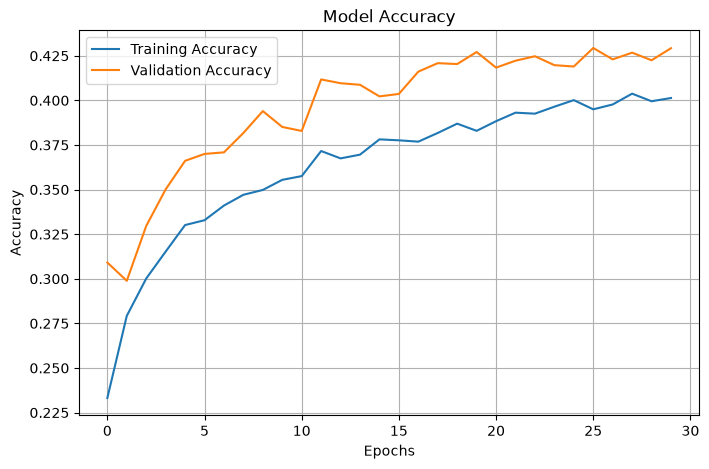

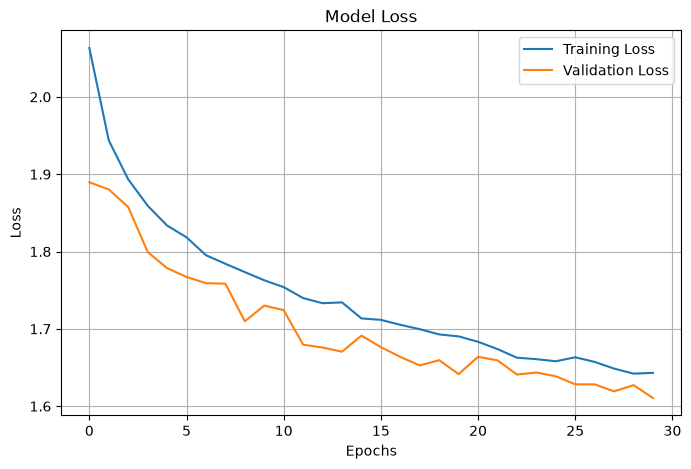

In [23]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [24]:
test_loss, test_accuracy = model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4350 - loss: 1.6175


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


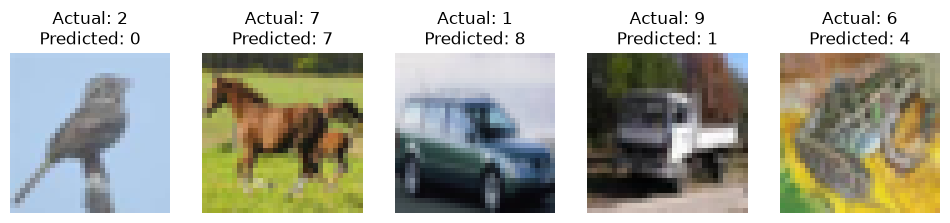

In [25]:
predicted = model.predict(x_test)
predictions = np.argmax(predicted, axis=1)

plt.figure(figsize=(12,5))

for i in range(5):
    plt.subplot(1,5,i+1)

    plt.imshow(x_test[i].reshape(32,32,3))

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {predictions[i]}"
    )

    plt.axis("off")

plt.show()

In [26]:
import os

print(os.getcwd())

C:\Users\user5\Desktop\practicals_notebook\CIFAR-10
